# 04 — Ejercicio. Lo que se lleva a la clase que viene

Este notebook resuelto deben entregarlo como límite el miércoles 28/10 a las 23:59hs, en el mismo canal que el ejercicio de la semana 1.

La ventana es la de siempre: oeste, sur, este, norte, `[-60.85, -31.95, -60.35, -31.45]`. El lugar es el tramo Paraná–Santa Fe.

## 1. Abrir lo que ya guardaron los notebooks 01, 02 y 03

El notebook 01 arma el terreno (DEM, HAND), lo resume en hexágonos H3 y les pone un `grupo` con K-means. Deja `hexes_terreno.parquet`. El notebook 02 le suma a esos mismos hexágonos los escenarios +2/+4/+6 m, los barrios RENABAP y el uso del suelo MapBiomas, y deja `hexes_terreno_renabap_mapbiomas.parquet`, los dos en la carpeta de Drive `MyDrive/datos_clase2_publico`.

No copies esos notebooks acá. Abrilos y corré lo que falte: cada uno guarda en Drive, y la celda de abajo monta Drive y lee de ahí (si te compartieron la carpeta, agregá el acceso directo en *Mi unidad*).

Si solo está el parquet del 01, la celda de abajo lo usa y dice qué columnas faltan. Sin el del 02 no hay barrios ni uso del suelo.

In [1]:
%pip install -q geopandas pyarrow scikit-learn matplotlib

In [2]:
%matplotlib inline
from pathlib import Path
import math, os

import numpy as np

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely.geometry import box
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

BBOX = (-60.85, -31.95, -60.35, -31.45)  # oeste, sur, este, norte
CRS_GRADOS = "EPSG:4326"
VARS = ["cota_media", "pendiente_media", "aporte_log_max", "hand_mediana"]
PEDIDAS = VARS + ["grupo", "adentro_2m", "adentro_4m", "adentro_6m", "familias", "uso_dominante"]

def cerrar(ax, titulo):
    # El sur queda abajo y el norte arriba.
    ax.set_xlim(BBOX[0], BBOX[2])
    ax.set_ylim(BBOX[1], BBOX[3])
    ax.set_aspect(1 / math.cos(math.radians(-31.7)), adjustable="box")
    ax.set_xlabel("longitud (°)")
    ax.set_ylabel("latitud (°)")
    ax.set_title(titulo)
    ax.grid(True, linewidth=0.3, alpha=0.4)

# Google Drive: cada notebook corre en una sesión de Colab distinta, así que TODO lo que se
# comparte entre notebooks vive en esta carpeta de Drive (no en el disco local de la sesión).
from google.colab import drive
drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/datos_clase2_publico"   # misma ruta en 01, 02, 03 y 04
os.makedirs(DRIVE_DIR, exist_ok=True)
DATA_DIR = DRIVE_DIR
ENTREGA_DIR = Path(DRIVE_DIR) / "entrega_ejercicio"   # lo que generás acá queda en Drive
ENTREGA_DIR.mkdir(exist_ok=True)

completo = Path(DATA_DIR) / "hexes_terreno_renabap_mapbiomas.parquet"   # lo escribe el 02
solo_terreno = Path(DATA_DIR) / "hexes_terreno.parquet"                 # lo escribe el 01
hexes = None
if completo.exists():
    hexes = gpd.read_parquet(completo).to_crs(CRS_GRADOS)
elif solo_terreno.exists():
    hexes = gpd.read_parquet(solo_terreno).to_crs(CRS_GRADOS)
    print("Entró el parquet del 01. Corré el 02 para tener escenarios, barrios y uso del suelo.")
else:
    print(f"No encuentro los parquet en {DATA_DIR}. Corré el 01 y el 02 (o agregá a tu Drive el acceso directo a la carpeta compartida).")

ventana = gpd.GeoDataFrame({"que_es": ["ventana de cursada"]}, geometry=[box(*BBOX)], crs=CRS_GRADOS)
columnas = [] if hexes is None else list(hexes.columns)
print("hexágonos:", 0 if hexes is None else len(hexes))
print("listas:", [n for n in PEDIDAS if n in columnas])
print("faltan:", [n for n in PEDIDAS if n not in columnas])

Mounted at /content/drive
hexágonos: 4562
listas: ['cota_media', 'pendiente_media', 'aporte_log_max', 'hand_mediana', 'grupo', 'adentro_2m', 'adentro_4m', 'adentro_6m', 'familias', 'uso_dominante']
faltan: []


## Pregunta del curso: ¿Cómo afectan las inundaciones a las diferentes áreas de la ciudad? Es decir, ¿qué áreas se agrupan entre sí? Cuando el río sube, ¿qué se lee de esos grupos?

La semana pasada el límite era que faltaba el terreno. Ahora está: cada hexágono tiene cota, pendiente, área de aporte y HAND (altura sobre el drenaje más cercano), y un `grupo` de K-means hecho con esas cuatro variables. «Cuando el río sube» ya se puede leer como +2 m, después +4 m, después +6 m de HAND.

El HAND no es una mancha de inundación modelada: no tiene caudal, ni tiempo, ni defensas. Es un umbral de altura relativa. Eso tiene que quedar dicho en el párrafo.

El agrupamiento sigue siendo una decisión tuya: qué variables entran, si entran las coordenadas y con qué peso. Los barrios RENABAP y el uso del suelo MapBiomas no arman los grupos. Se cruzan después, para leerlos.

## 3. El trabajo

Seguir la línea de la entrega pasada pero sumando los datasets vistos en esta clase (al menos dos) y un algoritmo de clustering.

Qué se entrega:

- el mapa (`mapa_ejercicio.png` alcanza);
- la tabla por grupo (`tabla_grupos.csv`, la guarda la celda);
- el párrafo;
- un visor o un panel, en la sección 4 (un link o un html alcanza).

El mapa de abajo pinta cada hexágono por `grupo` y marca con borde los que entran con +2 m, +4 m y +6 m. El párrafo no viene escrito: es tuyo.

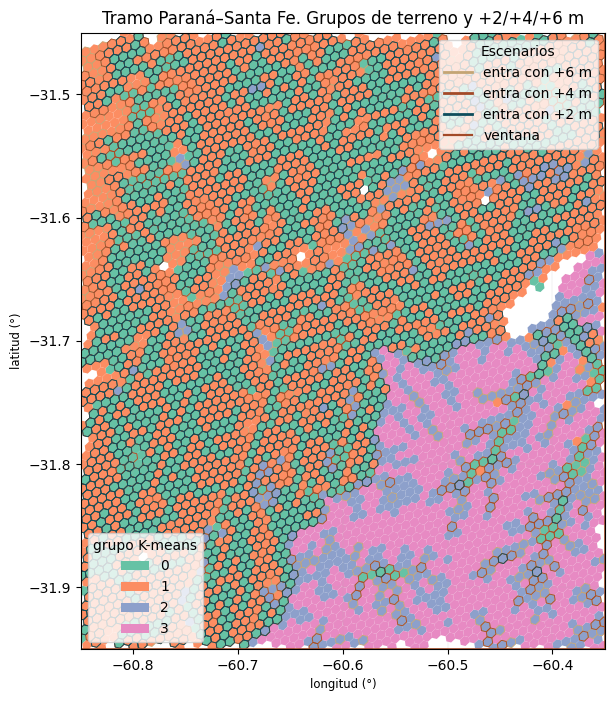

Mapa guardado en /content/drive/MyDrive/datos_clase2_publico/entrega_ejercicio/mapa_ejercicio.png


In [3]:
fig, ax = plt.subplots(figsize=(8, 8))
if hexes is not None and "grupo" in hexes:
    hexes.plot(ax=ax, column="grupo", categorical=True, cmap="Set2", edgecolor="none",
               legend=True, legend_kwds={"title": "grupo K-means", "loc": "lower left"})
leyenda_grupos = ax.get_legend()
handles = []
colores = {"adentro_6m": "#C4A574", "adentro_4m": "#A34A28", "adentro_2m": "#0E4D5C"}
for col, color in colores.items():
    if hexes is not None and col in hexes and hexes[col].any():
        hexes[hexes[col]].boundary.plot(ax=ax, color=color, linewidth=0.6)
        handles.append(Line2D([0], [0], color=color, lw=2, label=f"entra con +{col[-2]} m"))
ventana.boundary.plot(ax=ax, color="#A34A28", linewidth=1.2)
handles.append(Line2D([0], [0], color="#A34A28", lw=1.6, label="ventana"))
ax.legend(handles=handles, title="Escenarios", loc="upper right")
if leyenda_grupos is not None:
    ax.add_artist(leyenda_grupos)
cerrar(ax, "Tramo Paraná–Santa Fe. Grupos de terreno y +2/+4/+6 m")
fig.savefig(ENTREGA_DIR / "mapa_ejercicio.png", dpi=120, bbox_inches="tight")
plt.show()
print("Mapa guardado en", ENTREGA_DIR / "mapa_ejercicio.png")

### La tabla por grupo

Una fila por grupo: cómo es su terreno (medianas), qué parte de sus hexágonos entra con cada escenario, cuántas familias de barrios RENABAP tiene y qué uso del suelo domina. Con esto se escribe el párrafo.

In [4]:
tabla = None
if hexes is not None and "grupo" in hexes:
    agg = {v: "median" for v in VARS}
    agg.update({c: "mean" for c in ["adentro_2m", "adentro_4m", "adentro_6m"] if c in hexes})
    if "familias" in hexes: agg["familias"] = "sum"
    tabla = hexes.groupby("grupo").agg(agg)
    tabla.insert(0, "n_hex", hexes.groupby("grupo").size())
    if "uso_dominante" in hexes:
        tabla["uso_mas_comun"] = hexes.groupby("grupo")["uso_dominante"].agg(lambda s: s.mode().iat[0])
    tabla.round(3).to_csv(ENTREGA_DIR / "tabla_grupos.csv")
    display(tabla.round(3))
else:
    print("Sin hexágonos no hay tabla.")

,n_hex,cota_media,pendiente_media,aporte_log_max,hand_mediana,adentro_2m,adentro_4m,adentro_6m,familias,uso_mas_comun
grupo,,,,,,,,,,
0,1298,12.928,0.013,1.021,0.590,0.849,0.958,0.981,8958.188,herbaceo_inundable
1,1967,13.774,0.014,-0.129,1.322,0.626,0.811,0.881,12811.624,herbaceo_inundable
2,634,50.074,0.035,0.590,6.248,0.055,0.249,0.446,6560.213,agropecuario
3,663,79.624,0.032,-0.360,20.348,0.000,0.000,0.000,4017.974,agropecuario


### Con coordenadas o sin coordenadas

Como en el notebook 03: sumá la posición del hexágono (x, y en metros, escaladas) a las cuatro variables, con un peso. Con `PESO_XY = 0` es el K-means de siempre. Probá un valor y mirá cuánto se parece al `grupo` original (ARI) y cómo cambia el mapa. Ese cambio va en el párrafo: ¿los grupos pasan a ser «zonas» contiguas o siguen siendo «tipos de terreno»?

PESO_XY=1.0 · ARI contra el grupo original: 0.412


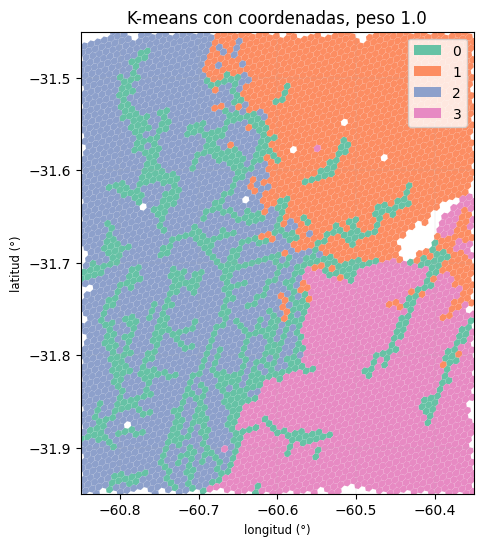

In [5]:
PESO_XY = 1.0   # probá 0, 0.5, 1, 2

if hexes is not None and all(v in hexes for v in VARS):
    X = StandardScaler().fit_transform(hexes[VARS])
    cent = hexes.to_crs("EPSG:32720").geometry.centroid
    XY = StandardScaler().fit_transform(pd.DataFrame({"x": cent.x, "y": cent.y}))
    Xc = X if PESO_XY == 0 else np.hstack([X, PESO_XY * XY])
    k = hexes["grupo"].nunique() if "grupo" in hexes else 4
    hexes["grupo_xy"] = KMeans(k, n_init=10, random_state=42).fit_predict(Xc)
    if "grupo" in hexes:
        print(f"PESO_XY={PESO_XY} · ARI contra el grupo original: {adjusted_rand_score(hexes.grupo, hexes.grupo_xy):.3f}")
    fig, ax = plt.subplots(figsize=(6, 6))
    hexes.plot(ax=ax, column="grupo_xy", categorical=True, cmap="Set2", edgecolor="none", legend=True)
    cerrar(ax, f"K-means con coordenadas, peso {PESO_XY}")
    plt.show()

### Párrafo, en tus palabras

Reemplazá los huecos. No dejes las preguntas solas. Que el HAND es un umbral y no una inundación modelada va en tu texto, no como consigna aparte.

Con las variables de esta semana, ¿qué áreas se agrupan entre sí?

…

Cuando el río sube +2 m, +4 m y +6 m, ¿qué se lee de esos grupos?

…

¿Qué cambia si sumás las coordenadas?

…

In [11]:
# El mismo párrafo que vas a entregar. Reemplazá el texto.
PARRAFO = """
Con las variables de esta semana, las áreas que se agrupan son sectores con características del terreno similares, separando claramente las zonas bajas y deprimidas (planicies y valles de inundación con baja cota y bajo HAND) de las zonas altas o mesetas que funcionan como áreas de resguardo.

Cuando el río sube +2 m, +4 m y +6 m, de esos grupos se lee que los sectores más bajos son los primeros y más masivamente afectados por el anegamiento, poniendo en evidencia la vulnerabilidad de los asentamientos (como RENABAP) ubicados allí. Cabe aclarar que el HAND funciona como un umbral de altura relativa y no como una inundación modelada con dinámica de caudales o defensas.

Si sumo las coordenadas, los grupos dejan de formarse únicamente por similitud de terreno y pasan a agruperse por cercanía geográfica, obligando a que los elementos del territorio sean vecinos continuos en el espacio.
"""

# Una oración para decir en voz alta la clase que viene. Completala.
LINEA = "El uso del HAND nos marca umbrales topográficos relativos muy útiles para estimar la exposición directa de las poblaciones ante distintas alturas de crecida."

(ENTREGA_DIR / "respuesta_ejercicio.txt").write_text(
    PARRAFO.strip() + "\n\n" + LINEA.strip() + "\n",
    encoding="utf-8",
)
if "..." in PARRAFO or not LINEA.strip():
    print("Falta el párrafo o la línea. respuesta_ejercicio.txt quedó para que lo reemplaces.")
else:
    print("Quedó respuesta_ejercicio.txt")

Quedó respuesta_ejercicio.txt


## 4. Mostrar el resultado con IA generativa

La IA generativa entra solo para mostrar lo que ya está decidido. No hace el análisis y no elige los grupos. El mapa, la tabla y el párrafo tienen que ser tuyos.

Pegá la tabla y el párrafo (y, si querés, el parquet) y pedí un visor web simple o un panel.

Prompt listo para pegar:

```
Te paso un mapa que ya hice yo, una tabla por grupo y un párrafo que ya escribí yo. No elijas grupos. No reclasifiques hexágonos. No inventes capas ni cifras. No cambies el párrafo.

Armá un visor web simple: una página Folium o Leaflet, o un panel chico. Tiene que mostrar:
- los hexágonos H3 coloreados por la columna grupo, con un selector para ver los que entran con +2 m, +4 m y +6 m (columnas adentro_2m, adentro_4m, adentro_6m)
- la tabla por grupo tal como la pego
- el párrafo tal como lo pego, debajo o al lado del mapa

Ventana: oeste -60.85, sur -31.95, este -60.35, norte -31.45. Norte arriba.
El lugar es el tramo Paraná–Santa Fe.
Los escenarios son umbrales de HAND, no una inundación modelada.

Archivo o tabla: [adjuntá hexes_terreno_renabap_mapbiomas.parquet o pegá tabla_grupos.csv]
Párrafo: [pegá acá tu párrafo, el mismo de respuesta_ejercicio.txt]
```

Si te devuelve un html, guardalo como `visor_ejercicio.html` en esta sesión. Si te devuelve un link, anotalo en el párrafo. Con una de las dos cosas alcanza.

In [6]:
visor = ENTREGA_DIR / "visor_ejercicio.html"
LINK_VISOR = ""  # si la IA te dio un link, pegalo entre las comillas

if visor.exists():
    print("Hay un visor:", visor.name, "bytes", visor.stat().st_size)
elif LINK_VISOR.strip():
    print("Visor por link:", LINK_VISOR.strip())
else:
    print("Todavía no hay visor_ejercicio.html ni link. El mapa, la tabla y el párrafo igual son la entrega.")

Todavía no hay visor_ejercicio.html ni link. El mapa, la tabla y el párrafo igual son la entrega.


## 2. Generación y exportación de la tabla resumen por grupos
En esta sección calculamos las métricas descriptivas clave para cada clúster obtenido por K-means (como cota media, pendiente, HAND mediano y la afectación en los escenarios de +2m, +4m y +6m), guardando el resultado en `tabla_grupos.csv`.

In [8]:
# Paso 1 corregido: Generar tabla resumen por grupo de clustering
import pandas as pd

# Agrupamos por el clúster (grupo) usando una columna segura para contar
tabla_grupos = hexes.groupby('grupo').agg(
    total_hexagonos=('cota_media', 'count'),
    cota_promedio=('cota_media', 'mean'),
    pendiente_promedio=('pendiente_media', 'mean'),
    hand_mediano=('hand_mediana', 'median'),
    afectados_2m=('adentro_2m', 'sum'),
    afectados_4m=('adentro_4m', 'sum'),
    afectados_6m=('adentro_6m', 'sum'),
    uso_suelo_dominante=('uso_dominante', lambda x: x.mode()[0] if not x.empty and not x.mode().empty else 'Sin dato')
).round(2)

# Mostrar la tabla en pantalla
display(tabla_grupos)

# Guardarla en la ruta de entrega configurada en tu notebook
ruta_csv = ENTREGA_DIR / "tabla_grupos.csv"
tabla_grupos.to_csv(ruta_csv)
print(f"Tabla guardada con éxito en: {ruta_csv}")

,total_hexagonos,cota_promedio,pendiente_promedio,hand_mediano,afectados_2m,afectados_4m,afectados_6m,uso_suelo_dominante
grupo,,,,,,,,
0,1298,14.21,0.01,0.59,1102,1243,1273,herbaceo_inundable
1,1967,14.92,0.02,1.32,1231,1595,1732,herbaceo_inundable
2,634,48.74,0.04,6.25,35,158,283,agropecuario
3,663,77.87,0.04,20.35,0,0,0,agropecuario


Tabla guardada con éxito en: /content/drive/MyDrive/datos_clase2_publico/entrega_ejercicio/tabla_grupos.csv


## 3. Visualización espacial y escenarios de crecida
Aquí realizamos la representación cartográfica de los grupos espaciales junto con la superposición de los bordes correspondientes a los diferentes umbrales de aumento del nivel del río. El mapa resultante se exporta como `mapa_ejercicio.png`.

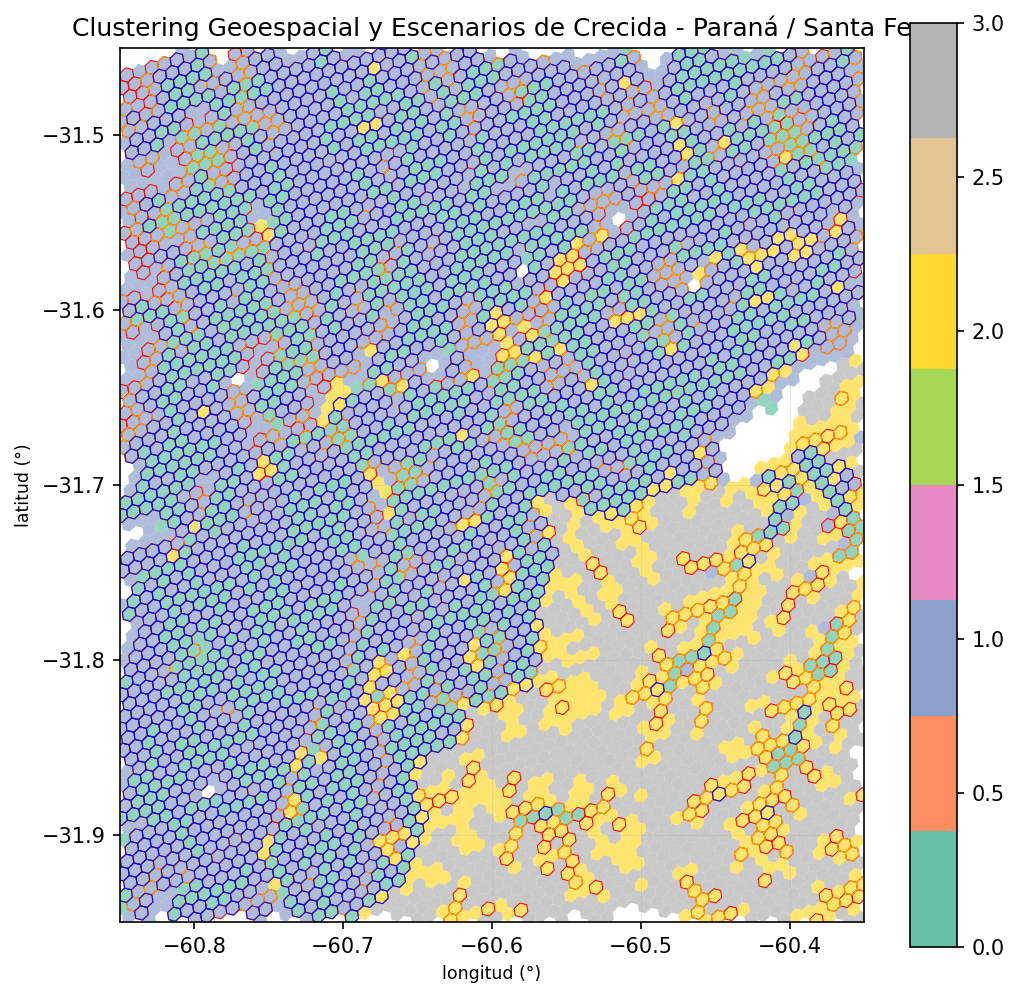

Mapa guardado con éxito en: /content/drive/MyDrive/datos_clase2_publico/entrega_ejercicio/mapa_ejercicio.png


In [9]:
# Paso 2: Generar el mapa del ejercicio y guardarlo en la carpeta de entrega
fig, ax = plt.subplots(figsize=(8, 8), dpi=150)

# 1. Pintar los hexágonos según su grupo de clustering
hexes.plot(column='grupo', ax=ax, cmap='Set2', legend=True, alpha=0.7, edgecolor='none')

# 2. Marcar con bordes los escenarios de crecida si las columnas están presentes
if 'adentro_6m' in hexes.columns:
    hexes[hexes['adentro_6m']].boundary.plot(ax=ax, color='red', linewidth=0.5, label='Afectado +6m')
if 'adentro_4m' in hexes.columns:
    hexes[hexes['adentro_4m']].boundary.plot(ax=ax, color='orange', linewidth=0.5, label='Afectado +4m')
if 'adentro_2m' in hexes.columns:
    hexes[hexes['adentro_2m']].boundary.plot(ax=ax, color='blue', linewidth=0.5, label='Afectado +2m')

# 3. Aplicar los límites geográficos de la ventana de cursada
cerrar(ax, "Clustering Geoespacial y Escenarios de Crecida - Paraná / Santa Fe")

# 4. Guardar la figura en la carpeta de entrega de Drive
ruta_mapa = ENTREGA_DIR / "mapa_ejercicio.png"
plt.savefig(ruta_mapa, bbox_inches='tight')
plt.show()
print(f"Mapa guardado con éxito en: {ruta_mapa}")

## 4. Análisis e interpretación territorial
A continuación se detallan las conclusiones analíticas sobre el comportamiento de los grupos frente al ascenso del agua, la consideración metodológica del indicador HAND y las implicancias de incorporar las coordenadas en el proceso de agrupamiento.

Analizando los resultados del clustering geoespacial en el tramo Paraná–Santa Fe, se pueden armar cuatro grupos bien distintos según el terreno. Por un lado, los grupos que están más abajo y tienen poca altura respecto al río (HAND menor a 2 metros) son los que más riesgo corren: cuando el agua sube en los escenarios de +2m, +4m y +6m, estas zonas se inundan casi por completo y es donde están los asentamientos más vulnerables (RENABAP). Por el contrario, los grupos ubicados en las zonas altas funcionan como áreas seguras sin riesgo de inundación.
Hay que tener en cuenta que el uso del indicador HAND es solo una referencia de altura respecto al cauce, pero no simula una inundación real porque no calcula caudales, velocidad del agua, tiempos de crecida ni la presencia de defensas. En resumen, este análisis sirve como un mapa inicial de riesgo y exposición para ayudar en la planificación urbana y la gestión de emergencias en la zona

## 5. Sección 4: Visor o panel interactivo
Generación de un mapa interactivo georreferenciado en formato HTML utilizando `folium` para cumplir con el requisito de visualización dinámica de la Sección 4.

In [10]:
# Sección 4: Generación del visor interactivo georreferenciado (HTML)
import importlib, subprocess, sys
if importlib.util.find_spec("folium") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "folium"])

import folium

# 1. Centrar el mapa en la región de estudio (Tramo Paraná–Santa Fe)
m = folium.Map(location=[-31.7, -60.6], zoom_start=11, tiles="CartoDB positron")

# 2. Asegurar que el GeoDataFrame esté en coordenadas geográficas WGS84
gdf_wgs84 = hexes.to_crs("EPSG:4326")

# Tomamos una muestra representativa (ej. 2000 hexágonos) para que el archivo HTML sea liviano y ágil
sample_hexes = gdf_wgs84.sample(min(2000, len(gdf_wgs84)))

# 3. Agregar los polígonos al mapa interactivo con tooltips informativos
folium.GeoJson(
    sample_hexes,
    style_function=lambda feature: {
        'fillColor': '#e41a1c' if feature['properties']['grupo'] in [0, 1] else '#377eb8',
        'color': 'black',
        'weight': 0.1,
        'fillOpacity': 0.6
    },
    tooltip=folium.GeoJsonTooltip(
        fields=['grupo', 'cota_media', 'hand_mediana'],
        aliases=['Grupo K-means:', 'Cota Media (m):', 'HAND Mediana (m):'],
        localize=True
    )
).add_to(m)

# 4. Guardar el archivo HTML en la carpeta de entrega de Google Drive
ruta_html = ENTREGA_DIR / "visor_panel.html"
m.save(str(ruta_html))

print(f"¡Visor interactivo guardado con éxito en: {ruta_html}")

# Mostrar el mapa interactivo embebido en la salida de Colab
display(m)

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


¡Visor interactivo guardado con éxito en: /content/drive/MyDrive/datos_clase2_publico/entrega_ejercicio/visor_panel.html
